#**Sales Analysis**

In [1]:
import pandas as pd

df = pd.read_csv("/content/sales_performance_portfolio_dataset.csv")

df.head()

,Order_ID,Order_Date,Customer,Product,Category,Region,Salesperson,Quantity,Unit_Price,Discount,Sales,Cost,Profit
0,ORD-03674,2024-01-01,Customer_0254,Printer,Office Equipment,West,Meena,7,294.74,0.15,1753.71,1442.03,311.68
1,ORD-02259,2024-01-01,Customer_0358,Laptop,Electronics,North,Rahul,5,668.50,0.10,3008.26,2200.21,808.06
2,ORD-02316,2024-01-01,Customer_0444,Laptop,Electronics,North,Meena,1,752.60,0.00,752.60,566.44,186.16
3,ORD-02442,2024-01-01,Customer_0120,Laptop,Electronics,North,Rahul,8,1046.26,0.05,7951.61,6166.05,1785.56
4,ORD-01488,2024-01-01,Customer_0305,Desk Chair,Furniture,West,Priya,4,200.26,0.10,720.92,482.45,238.47


In [2]:
df.tail()

,Order_ID,Order_Date,Customer,Product,Category,Region,Salesperson,Quantity,Unit_Price,Discount,Sales,Cost,Profit
5003,ORD-03649,2025-12-31,Customer_0464,Tablet,Electronics,North,Anitha,2,235.87,0.05,448.16,350.65,97.50
5004,ORD-01336,2025-12-31,Customer_0489,Printer,Office Equipment,North,Karthik,6,279.17,0.05,1591.27,1114.43,476.84
5005,ORD-04422,2025-12-31,Customer_0388,External SSD,Electronics,East,Priya,3,212.01,0.05,604.23,361.06,243.18
5006,ORD-03712,2025-12-31,Customer_0197,Webcam,Electronics,West,Sanjay,1,75.29,0.00,75.29,60.02,15.27
5007,ORD-00820,2025-12-31,Customer_0074,Mouse,Accessories,South,Arun,8,54.48,0.05,414.06,333.05,81.01


In [3]:
df.shape

(5008, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5008 entries, 0 to 5007
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Order_ID     5008 non-null   object 
 1   Order_Date   5008 non-null   object 
 2   Customer     4996 non-null   object 
 3   Product      5008 non-null   object 
 4   Category     5008 non-null   object 
 5   Region       5008 non-null   object 
 6   Salesperson  5000 non-null   object 
 7   Quantity     5008 non-null   int64  
 8   Unit_Price   5008 non-null   float64
 9   Discount     5003 non-null   float64
 10  Sales        5008 non-null   float64
 11  Cost         5008 non-null   float64
 12  Profit       5008 non-null   float64
dtypes: float64(5), int64(1), object(7)
memory usage: 508.8+ KB


In [5]:
df.describe()

,Quantity,Unit_Price,Discount,Sales,Cost,Profit
count,5008.000000,5008.000000,5003.000000,5008.000000,5008.000000,5008.000000
mean,4.464457,228.915883,0.068799,964.641456,686.918419,277.722941
std,2.292200,246.686884,0.057564,1279.090635,925.784114,379.888359
min,1.000000,15.190000,0.000000,13.740000,8.110000,2.460000
25%,2.000000,57.860000,0.000000,197.960000,139.775000,55.350000
50%,4.000000,151.445000,0.050000,501.170000,351.530000,137.610000
75%,6.000000,276.650000,0.100000,1188.075000,834.765000,343.160000
max,8.000000,1099.850000,0.200000,8758.690000,7266.180000,3034.980000


In [6]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer', 'Product', 'Category', 'Region',
       'Salesperson', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost',
       'Profit'],
      dtype='object')

In [7]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer,12
Product,0
Category,0
Region,0
Salesperson,8
Quantity,0
Unit_Price,0
Discount,5


In [8]:
df.duplicated().sum()

np.int64(8)

##**cleaning**

In [9]:
clean_df = df.copy()

In [10]:
clean_df.to_csv("cleaned_sales_data.csv", index=False)

In [11]:
import os

print(os.getcwd())

/content


## Handling null values

In [12]:
(clean_df.isnull().sum() / len(clean_df) * 100).round(2)

,0
Order_ID,0.00
Order_Date,0.00
Customer,0.24
Product,0.00
Category,0.00
Region,0.00
Salesperson,0.16
Quantity,0.00
Unit_Price,0.00
Discount,0.10


In [13]:
clean_df["Customer"] = clean_df["Customer"].fillna("Unknown")

In [14]:
clean_df["Salesperson"] = clean_df["Salesperson"].fillna("Unknown")

In [15]:
clean_df["Discount"].median()

0.05

In [16]:
clean_df["Discount"] = clean_df["Discount"].fillna(
    clean_df["Discount"].median()
)

##**Handling duplicates**

In [17]:
clean_df[clean_df.duplicated()]

,Order_ID,Order_Date,Customer,Product,Category,Region,Salesperson,Quantity,Unit_Price,Discount,Sales,Cost,Profit
141,ORD-01869,2024-01-23,Customer_0123,Monitor,Electronics,West,Rahul,7,204.03,0.05,1356.80,1013.37,343.43
1154,ORD-03336,2024-06-15,Customer_0325,Laptop,Electronics,North,Sanjay,4,811.76,0.05,3084.70,1983.69,1101.01
1799,ORD-03407,2024-09-16,Customer_0462,Headset,Accessories,East,Meena,3,95.33,0.10,257.39,208.61,48.79
1935,ORD-00758,2024-10-07,Customer_0177,Mouse,Accessories,South,Divya,2,39.88,0.15,67.80,45.52,22.27
2259,ORD-04545,2024-11-22,Customer_0240,Tablet,Electronics,North,Meena,5,361.37,0.20,1445.47,970.03,475.44
2902,ORD-03236,2025-02-21,Customer_0440,Tablet,Electronics,South,Arun,3,189.93,0.00,569.79,420.90,148.90
3141,ORD-02917,2025-03-29,Customer_0105,Laptop,Electronics,South,Karthik,5,1057.56,0.15,4494.65,3616.02,878.63
4161,ORD-03625,2025-08-31,Customer_0409,Laptop,Electronics,West,Priya,2,837.48,0.05,1591.21,943.03,648.18


In [18]:
clean_df = clean_df.drop_duplicates()

In [19]:
clean_df.duplicated().sum()

np.int64(0)

## Check Datatypes

In [20]:
clean_df["Order_Date"] = pd.to_datetime(clean_df["Order_Date"])

In [21]:
clean_df.dtypes

,0
Order_ID,object
Order_Date,datetime64[ns]
Customer,object
Product,object
Category,object
Region,object
Salesperson,object
Quantity,int64
Unit_Price,float64
Discount,float64


##**Check for impossible values**

In [22]:
(clean_df["Quantity"] <= 0).sum()

np.int64(0)

In [23]:
(clean_df["Sales"] < 0).sum()

np.int64(0)

In [24]:
(clean_df["Profit"] < 0).sum()

np.int64(0)

## **After cleaning**

In [25]:
clean_df.shape

(5000, 13)

In [26]:
clean_df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer,0
Product,0
Category,0
Region,0
Salesperson,0
Quantity,0
Unit_Price,0
Discount,0


## **Exploratory Data Analysis (EDA)**

In [27]:
## total sales
total_sales = clean_df["Sales"].sum()
print(total_sales)

4818056.6


In [28]:
## total profit
total_profit = clean_df["Profit"].sum()
print(total_profit)

1387169.84


In [29]:

## profit_margin
profit_margin = (total_profit / total_sales) * 100
print(profit_margin)

28.791065675733247


In [30]:
## total quantity sold
total_quantity = clean_df["Quantity"].sum()
print(total_quantity)

22327


In [31]:
## average_order value
average_order = clean_df["Sales"].mean()
print(average_order)

963.61132


In [32]:
## sales_byRegion
region_sales = clean_df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region_sales)

Region
South    1366086.49
West     1192015.22
North    1139071.50
East     1120883.39
Name: Sales, dtype: float64


In [33]:
##Top_5products
top_products = (
    clean_df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

print(top_products)

Product
Laptop         1858450.90
Tablet          615883.55
Monitor         540798.58
Office Desk     459944.12
Printer         309445.06
Name: Sales, dtype: float64


In [34]:
##profit_bycategory
category_profit = (
    clean_df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)

Category
Electronics         970488.94
Furniture           221668.95
Accessories         105832.20
Office Equipment     89179.75
Name: Profit, dtype: float64


## **Data Visualization**

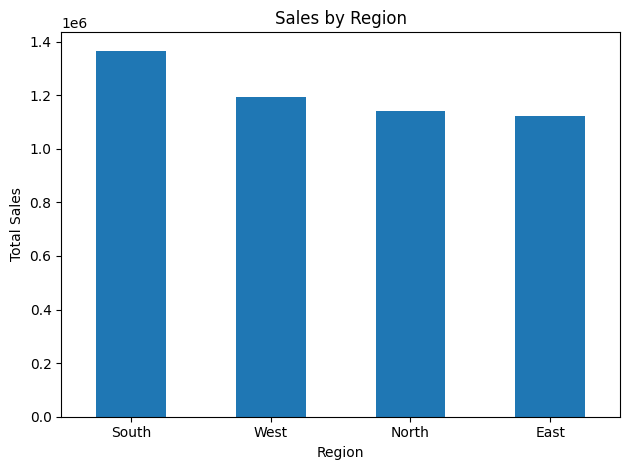

In [35]:
## totalsales_by region with bar chart
import matplotlib.pyplot as plt

region_sales = clean_df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

region_sales.plot(kind="bar")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

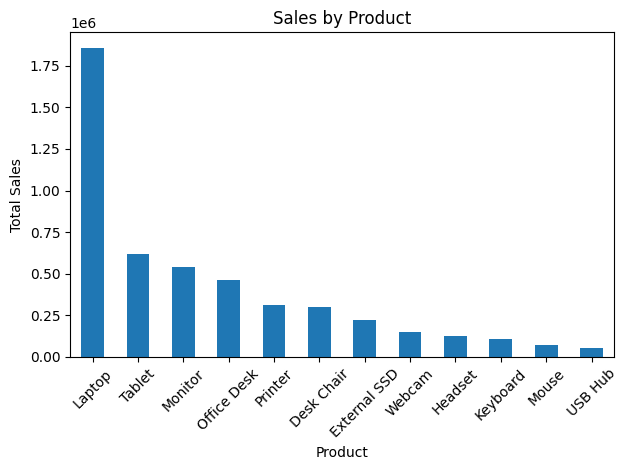

In [36]:
## totalsales_byproduct
product_sales = (
    clean_df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

product_sales.plot(kind="bar")

plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

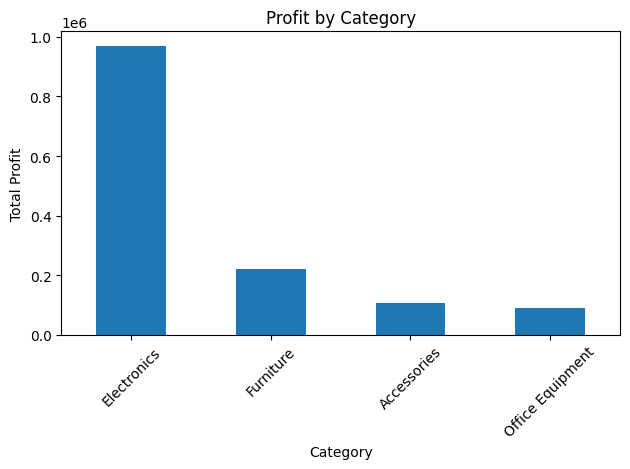

In [37]:
## profit by category
category_profit = (
    clean_df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit.plot(kind="bar")

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##**Monthly Sales Trend**

In [38]:
## Create a Month column
clean_df["Month"] = clean_df["Order_Date"].dt.to_period("M")

In [39]:
## Calculate monthly sales
monthly_sales = clean_df.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
2024-01    204099.11
2024-02    162061.99
2024-03    211161.40
2024-04    170628.43
2024-05    211907.20
2024-06    152562.35
2024-07    207064.44
2024-08    232426.66
2024-09    202161.53
2024-10    195455.66
2024-11    257935.63
2024-12    219237.41
2025-01    216825.40
2025-02    195092.41
2025-03    179833.18
2025-04    182264.29
2025-05    176190.20
2025-06    184692.36
2025-07    223196.78
2025-08    169287.83
2025-09    205843.79
2025-10    190496.55
2025-11    213212.52
2025-12    254419.48
Freq: M, Name: Sales, dtype: float64


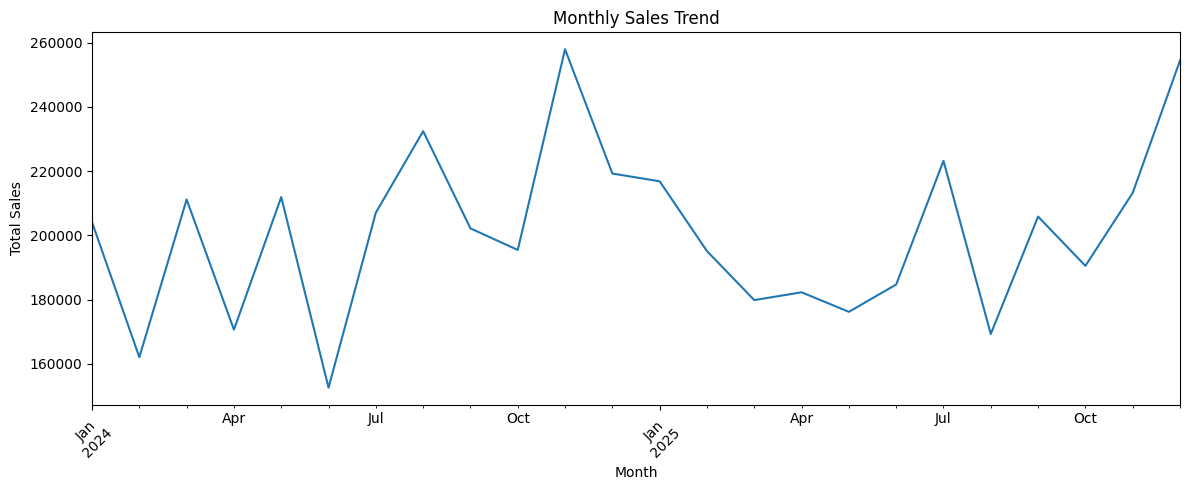

In [40]:
## Create the trend chart
monthly_sales.plot(kind="line", figsize=(12, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
## Find the best and worst months
print("Best month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Best month:
2024-11 257935.63

Lowest month:
2024-06 152562.35


Best month: November 2024 — 257,935.63
Lowest month: June 2024 — 152,562.35

That means November sales were about 69% higher than June sales. This is a useful business observation.

Sales showed a fluctuating monthly pattern during the two-year period, with noticeable peaks and dips. November 2024 recorded the highest monthly sales at 257,935.63, while June 2024 recorded the lowest at 152,562.35. Overall, 2025 showed stronger sales performance compared with 2024.

## **Profitability Analysis**

In [42]:
## Profit by Product
product_profit = (
    clean_df.groupby("Product")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(product_profit)

Product
Laptop          530973.64
Tablet          176729.50
Monitor         156134.67
Office Desk     133403.92
Printer          89179.75
Desk Chair       88265.03
External SSD     64756.08
Webcam           41895.05
Headset          36908.93
Keyboard         32152.90
Mouse            20464.27
USB Hub          16306.10
Name: Profit, dtype: float64


In [43]:
## Find the top 5 most profitable products
print(product_profit.head(5))

Product
Laptop         530973.64
Tablet         176729.50
Monitor        156134.67
Office Desk    133403.92
Printer         89179.75
Name: Profit, dtype: float64


In [44]:
## Find the bottom 5
product_summary = clean_df.groupby("Product").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

product_summary["Profit_Margin"] = (
    product_summary["Profit"] / product_summary["Sales"] * 100
)

product_summary = product_summary.sort_values(
    "Profit_Margin", ascending=False
)

print(product_summary)

                   Sales     Profit  Profit_Margin
Product                                           
Headset        125256.26   36908.93      29.466735
Mouse           69845.42   20464.27      29.299373
Desk Chair     301478.10   88265.03      29.277427
External SSD   222886.10   64756.08      29.053440
Keyboard       110682.26   32152.90      29.049732
Office Desk    459944.12  133403.92      29.004376
USB Hub         56477.60   16306.10      28.871801
Monitor        540798.58  156134.67      28.871132
Printer        309445.06   89179.75      28.819251
Tablet         615883.55  176729.50      28.695279
Laptop        1858450.90  530973.64      28.570765
Webcam         146908.65   41895.05      28.517756


In [45]:
product_summary.sort_values("Profit_Margin").head()

,Sales,Profit,Profit_Margin
Product,,,
Webcam,146908.65,41895.05,28.517756
Laptop,1858450.90,530973.64,28.570765
Tablet,615883.55,176729.50,28.695279
Printer,309445.06,89179.75,28.819251
Monitor,540798.58,156134.67,28.871132


A product with high sales or high total profit does not necessarily have the highest profit margin.

For example, Laptop generates the highest total profit, while Headset has the highest profit margin. This distinction is valuable in a real Data Analyst portfolio.

## **Region + Category together**


The product with the highest sales isn't necessarily the product with the highest profitability.

Then we'll analyze Region + Category together and start building insights that look much more like real business analysis.

In [46]:
region_category_profit = (
    clean_df.groupby(["Region", "Category"])["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(region_category_profit)

Region  Category        
South   Electronics         269563.28
East    Electronics         242798.01
West    Electronics         240041.68
North   Electronics         218085.97
South   Furniture            64210.54
North   Furniture            59703.61
West    Furniture            56915.78
East    Furniture            40839.02
South   Accessories          33193.19
West    Accessories          28494.15
North   Office Equipment     24495.38
South   Office Equipment     24323.40
East    Accessories          23131.55
North   Accessories          21013.31
East    Office Equipment     20657.81
West    Office Equipment     19703.16
Name: Profit, dtype: float64


##**Key findings**

-🏆 Highest profit: Electronics in the South region — 269,563.28.

-📉 Lowest profit: Office Equipment in the West region — 19,703.16.

-💻 Strongest category: Electronics generates the highest profit in all four regions.

-🪑 Furniture: The South region generates the highest profit from Furniture.

-⚠️ Office Equipment: It is a relatively weak profit contributor across all four regions.

**Maintain Electronics performance:** Investigate which products and sales strategies are contributing to its strong profits.

**Investigate the South region:** Understand why Electronics and Furniture perform particularly well there.

**Review Office Equipment:** Examine its pricing, costs, discounts, and sales volume to identify opportunities to improve profitability.

**Avoid assumptions:** Low profit alone does not prove that a category is performing badly. Compare its sales, costs, and profit margin before making a final recommendation.





**Regional Profitability Analysis:** Electronics was the strongest profit-generating category across all four regions. The South region recorded the highest profit from Electronics, at 269,563.28, while Office Equipment in the West recorded the lowest profit, at 19,703.16. These findings suggest that the business should investigate the factors driving Electronics profitability and examine opportunities to improve Office Equipment performance.

In [47]:
region_profit = (
    clean_df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(region_profit)

Region
South    391290.41
West     345154.77
East     327426.39
North    323298.27
Name: Profit, dtype: float64


The analysis shows that the South region has the highest total sales and the highest total profit in this synthetic dataset.

## **Customer Analysis**

In [48]:
customer_sales = (
    clean_df.groupby("Customer")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

print(customer_sales.head(10))

               Total_Sales  Total_Profit  Total_Orders
Customer                                              
Customer_0318     29644.86       8806.88            14
Customer_0231     28289.91       9111.65            15
Customer_0260     28237.10       8840.23             9
Customer_0207     27888.15       7152.51            13
Customer_0066     27459.19       8480.88            11
Customer_0083     26382.47       7640.70            16
Customer_0478     26355.44       7324.86            13
Customer_0136     25916.58       7039.19            16
Customer_0378     25817.44       8115.92            12
Customer_0479     25302.39       8361.03            16


**Results**

Based on answers:

-Highest total sales: Customer_0318

-Highest profit among the top 10 customers: Customer_0231

-Does the customer with the highest sales also generate the highest profit? No.

💡 **Business Insight**

The customer generating the highest sales is not necessarily the customer generating the highest profit.

This can happen because customers may purchase different products, receive different discounts, or generate different costs.

**Business recommendation:** The company should evaluate both sales and profit when identifying its most valuable customers, rather than ranking customers by sales alone.

You can include this finding in your portfolio, but remember that the dataset contains synthetic sample data.

## **Customer Segmentation**


In [49]:
customer_segments = customer_sales.copy()

customer_segments["Customer_Segment"] = pd.cut(
    customer_segments["Total_Sales"],
    bins=[-float("inf"), 500, 1500, float("inf")],
    labels=["Low Value", "Medium Value", "High Value"]
)

print(customer_segments["Customer_Segment"].value_counts())

Customer_Segment
High Value      497
Medium Value      4
Low Value         0
Name: count, dtype: int64


The dataset has 5,000 cleaned sales records, and the original dataset was designed with 500 customer IDs. The result totals 501 customers, which may mean a missing customer value was handled differently than expected.

Also, 497 out of 501 customers are classified as High Value. This suggests that spending thresholds may not be appropriate for this dataset.

Let's investigate before drawing conclusions.

### **Step 1: Check the customer sales distribution**

In [50]:
print(customer_sales["Total_Sales"].describe())

count      501.000000
mean      9616.879441
std       5305.351311
min       1152.510000
25%       5669.900000
50%       8861.170000
75%      12332.690000
max      29644.860000
Name: Total_Sales, dtype: float64


### **Step 2: Check the spending thresholds**

In [51]:
print(customer_sales["Total_Sales"].sort_values().head(10))
print(customer_sales["Total_Sales"].sort_values(ascending=False).head(10))

Customer
Customer_0047    1152.51
Customer_0033    1235.21
Customer_0364    1261.97
Customer_0041    1373.05
Customer_0097    1550.18
Customer_0222    1652.65
Customer_0371    1713.72
Customer_0094    1838.19
Customer_0395    1918.75
Customer_0303    2012.19
Name: Total_Sales, dtype: float64
Customer
Customer_0318    29644.86
Customer_0231    28289.91
Customer_0260    28237.10
Customer_0207    27888.15
Customer_0066    27459.19
Customer_0083    26382.47
Customer_0478    26355.44
Customer_0136    25916.58
Customer_0378    25817.44
Customer_0479    25302.39
Name: Total_Sales, dtype: float64


**Average vs. median:** Average customer sales are higher than median sales, suggesting that some high-spending customers pull the average upward.

**Spending variation:** Customer sales range from 1,152.51 to 29,644.86.

**Segmentation thresholds:** Our original thresholds of 500 and 1,500 were too low for this dataset.

In [52]:
print("Number of unique customer groups:", clean_df["Customer"].nunique())
print(clean_df[clean_df["Customer"] == "Unknown"].shape[0])

Number of unique customer groups: 501
12


**Improve customer segmentation**

Instead of choosing arbitrary spending thresholds, let's divide customers into three groups based on their actual spending distribution.

In [53]:
known_customers = customer_sales[
    ~customer_sales.index.isin(["Unknown"])
].copy()

known_customers["Customer_Segment"] = pd.qcut(
    known_customers["Total_Sales"],
    q=3,
    labels=["Low Value", "Medium Value", "High Value"]
)

print(known_customers["Customer_Segment"].value_counts())

Customer_Segment
Low Value       167
High Value      167
Medium Value    166
Name: count, dtype: int64


**Customer Segmentation Results**

There found 12 records with an unknown customer.

These records were created when missing customer names were replaced with "Unknown". Excluding that group from individual customer segmentation is appropriate because we cannot identify the actual customers.

These results show that your known customers have been divided into three approximately equal groups based on total sales.

Customer segmentation helps businesses develop targeted marketing strategies.

For example:

Low Value: Explore ways to encourage repeat purchases and increase order value.
Medium Value: Offer relevant product recommendations and bundles to encourage additional purchases.
High Value: Consider loyalty programs and personalized service to maintain customer relationships.

These are potential strategies, not proven recommendations. Additional analysis would be needed to determine which actions are likely to work.

Let's investigate whether high-value customers also generate the highest profits.

In [54]:
segment_analysis = known_customers.groupby(
    "Customer_Segment",
    observed=True
).agg(
    Total_Sales=("Total_Sales", "sum"),
    Total_Profit=("Total_Profit", "sum"),
    Customer_Count=("Total_Sales", "count")
)

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"]
    * 100
)

print(segment_analysis.round(2))

                  Total_Sales  Total_Profit  Customer_Count  Profit_Margin
Customer_Segment                                                          
Low Value           740824.02     215869.68             167          29.14
Medium Value       1472126.29     426659.95             166          28.98
High Value         2592939.95     740660.31             167          28.56


In [55]:
print(segment_analysis.sort_values("Profit_Margin", ascending=False))

                  Total_Sales  Total_Profit  Customer_Count  Profit_Margin
Customer_Segment                                                          
Low Value           740824.02     215869.68             167      29.139131
Medium Value       1472126.29     426659.95             166      28.982564
High Value         2592939.95     740660.31             167      28.564499


If the Low Value segment has the highest profit margin, it suggests that these customers generate more profit relative to their sales.

Remember the difference:

**Total profit** measures the amount of profit generated.

**Profit margin** measures profit as a percentage of sales.

A customer segment can generate less total profit but have a higher profit margin.